In [9]:
import json
import re
import time
import pandas as pd
import requests
from bs4 import BeautifulSoup
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [10]:
def ambil_data_top_anime(target_data=1500):
    url_utama = "https://myanimelist.net/topanime.php"

    headers = {
        "User-Agent": (
            "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
            "AppleWebKit/537.36 (KHTML, like Gecko) "
            "Chrome/120.0.0.0 Safari/537.36"
        )
    }

    daftar_anime = []
    offset = 0
    jumlah_per_halaman = 50

    while len(daftar_anime) < target_data:
        url = f"{url_utama}?limit={offset}"
        print(f"Terkumpul: {len(daftar_anime)} data")

        respon = requests.get(url, headers=headers, timeout=10)

        if respon.status_code != 200:
            print(
                f"Gagal mengakses halaman. Status Code: {respon.status_code}"
            )
            break

        soup = BeautifulSoup(respon.text, "html.parser")
        daftar_baris = soup.find_all("tr", class_="ranking-list")

        if not daftar_baris:
            print("Tidak ada elemen tabel '.ranking-list' yang ditemukan.")
            break

        for baris in daftar_baris:
            if len(daftar_anime) >= target_data:
                break

            el_rank = baris.find("td", class_="rank")
            teks_rank = el_rank.text.strip() if el_rank else None
            try:
                rank = int(teks_rank) if teks_rank else None
            except ValueError:
                rank = None

            el_judul = baris.find(
                "h3", class_="fl-l"
            ) or baris.find("h3", class_="anime_manga_title")
            if not el_judul:
                el_judul = baris.select_one("div.detail a")
            judul = el_judul.text.strip() if el_judul else None

            el_info = baris.find("div", class_="information")

            tipe_anime = None
            total_episodes = None
            total_members = None

            if el_info:
                teks_info = el_info.text.strip()
                baris_teks = [
                    baris_info.strip()
                    for baris_info in teks_info.split("\n")
                    if baris_info.strip()
                ]

                if len(baris_teks) > 0:
                    match_tipe_eps = re.search(
                        r"([A-Za-z0-9]+)\s*\((.*?)\)", baris_teks[0]
                    )
                    if match_tipe_eps:
                        tipe_anime = match_tipe_eps.group(1)
                        teks_eps = match_tipe_eps.group(2)
                        digit_eps = re.search(r"\d+", teks_eps)
                        total_episodes = (
                            int(digit_eps.group(0)) if digit_eps else None
                        )
                    else:
                        tipe_anime = baris_teks[0]

                for baris_info in baris_teks:
                    if "members" in baris_info.lower():
                        match_members = re.search(r"([\d,]+)", baris_info)
                        if match_members:
                            total_members = int(
                                match_members.group(1).replace(",", "")
                            )

            el_skor = baris.find("td", class_="score")
            teks_skor = el_skor.text.strip() if el_skor else None
            try:
                skor = (
                    float(teks_skor)
                    if teks_skor and teks_skor != "N/A"
                    else None
                )
            except ValueError:
                skor = None

            daftar_anime.append(
                {
                    "Rank": rank,
                    "Title": judul,
                    "Type": tipe_anime,
                    "Episodes": total_episodes,
                    "Score": skor,
                    "Members": total_members,
                }
            )

        offset += jumlah_per_halaman
        time.sleep(1)

    return daftar_anime


data_mentah = ambil_data_top_anime(target_data=1500)

df_anime = pd.DataFrame(data_mentah)
df_anime.to_csv("mal_top_anime_raw.csv", index=False, encoding="utf-8")

with open("mal_top_anime_raw.json", "w", encoding="utf-8") as f:
    json.dump(data_mentah, f, ensure_ascii=False, indent=4)

print("File CSV dan JSON berhasil disimpan.")

Terkumpul: 0 data
Terkumpul: 50 data
Terkumpul: 100 data
Terkumpul: 150 data
Terkumpul: 200 data
Terkumpul: 250 data
Terkumpul: 300 data
Terkumpul: 350 data
Terkumpul: 400 data
Terkumpul: 450 data
Terkumpul: 500 data
Terkumpul: 550 data
Terkumpul: 600 data
Terkumpul: 650 data
Terkumpul: 700 data
Terkumpul: 750 data
Terkumpul: 800 data
Terkumpul: 850 data
Terkumpul: 900 data
Terkumpul: 950 data
Terkumpul: 1000 data
Terkumpul: 1050 data
Terkumpul: 1100 data
Terkumpul: 1150 data
Terkumpul: 1200 data
Terkumpul: 1250 data
Terkumpul: 1300 data
Terkumpul: 1350 data
Terkumpul: 1400 data
Terkumpul: 1450 data
File CSV dan JSON berhasil disimpan.


In [11]:
df = pd.read_csv("mal_top_anime_raw.csv")

print("--- HEAD ---")
display(df.head())
print("\n--- INFO ---")
df.info()
print(f"\n--- SHAPE: {df.shape} ---")

--- HEAD ---


,Rank,Title,Type,Episodes,Score,Members
0,1,Sousou no Frieren,TV,28.0,9.25,1514421
1,2,Fullmetal Alchemist: Brotherhood,TV,64.0,9.11,3734710
2,3,Re:Zero kara Hajimeru Isekai Seikatsu 4th Season,TV,19.0,9.11,328172
3,4,Bleach: Sennen Kessen-hen - Kashin-tan,TV,10.0,9.09,164246
4,5,Steel Ball Run: JoJo no Kimyou na Bouken,ONA,NaN,9.08,233422



--- INFO ---
<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Rank      1500 non-null   int64  
 1   Title     1500 non-null   str    
 2   Type      1500 non-null   str    
 3   Episodes  1490 non-null   float64
 4   Score     1500 non-null   float64
 5   Members   1500 non-null   int64  
dtypes: float64(2), int64(2), str(2)
memory usage: 70.4 KB

--- SHAPE: (1500, 6) ---


## Klasifikasi Tipe Atribut Data Mining

| Atribut | Tipe Atribut | Keterangan |
|---|---|---|
| `Title` | Nominal | Label atau nama anime tanpa urutan tertentu |
| `Type` | Nominal | Kategori jenis anime tanpa urutan tertentu |
| `Rank` | Ordinal | Peringkat anime yang memiliki urutan |
| `Episodes` | Diskrit | Jumlah episode berupa bilangan cacah |
| `Members` | Diskrit | Jumlah anggota berupa bilangan cacah |
| `Score` | Kontinu | Nilai penilaian yang dapat berada pada rentang desimal |

In [12]:
df_anime["Members"] = (
    pd.to_numeric(
        df_anime["Members"].astype("string").str.replace(",", "", regex=False),
        errors="coerce",
    ).astype("Int64")
)

episodes_bersih = (
    df_anime["Episodes"]
    .astype("string")
    .replace("Unknown", pd.NA)
    .str.extract(r"(\d+)", expand=False)
)

df_anime["Episodes"] = pd.to_numeric(episodes_bersih, errors="coerce").astype("Int64")
df_anime["Score"] = pd.to_numeric(df_anime["Score"], errors="coerce").astype(float)
df_anime["Rank"] = pd.to_numeric(df_anime["Rank"], errors="coerce").astype("Int64")

score_median = df_anime["Score"].median()
df_anime["Score"] = df_anime["Score"].fillna(score_median)

print("Tipe data setelah pembersihan:")
print(df_anime[["Members", "Episodes", "Score", "Rank"]].dtypes)

Tipe data setelah pembersihan:
Members       Int64
Episodes      Int64
Score       float64
Rank          Int64
dtype: object


In [20]:
kolom_numerik = ["Score", "Members", "Episodes"]

stat_deskriptif = df_anime[kolom_numerik].agg(["mean", "median", "std", "min", "max"]).T
stat_deskriptif["modus"] = df_anime[kolom_numerik].mode().iloc[0]
stat_deskriptif = stat_deskriptif[["mean", "median", "modus", "std", "min", "max"]]

print("Statistik Deskriptif Numerik")
display(stat_deskriptif)

distribusi_tipe = df_anime["Type"].value_counts(dropna=False).to_frame("Jumlah")
distribusi_tipe["Persentase (%)"] = (distribusi_tipe["Jumlah"] / len(df_anime)) * 100

print("\nDistribusi Frekuensi Type")
display(distribusi_tipe)

ringkasan_kosong = df_anime.isna().sum().to_frame("Jumlah NaN")
print("\nRingkasan Missing Values")
display(ringkasan_kosong)

q1 = df_anime[kolom_numerik].quantile(0.25)
q3 = df_anime[kolom_numerik].quantile(0.75)
iqr = q3 - q1
batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

mask_outlier = (df_anime[kolom_numerik] < batas_bawah) | (df_anime[kolom_numerik] > batas_atas)
ringkasan_outlier = pd.DataFrame({
    "Q1": q1,
    "Q3": q3,
    "IQR": iqr,
    "Batas Bawah": batas_bawah,
    "Batas Atas": batas_atas,
    "Jumlah Outlier": mask_outlier.sum()
})

print("\nDeteksi Outlier dengan IQR")
display(ringkasan_outlier)

Statistik Deskriptif Numerik


,mean,median,modus,std,min,max
Score,8.074020,8.0,7.74,0.309696,7.69,9.25
Members,379747.800667,160163.5,1663.0,561325.544346,864.00,4425476.00
Episodes,18.924161,12.0,1.0,57.328905,1.00,1787.00



Distribusi Frekuensi Type


,Jumlah,Persentase (%)
Type,,
TV,796,53.066667
Movie,338,22.533333
ONA,160,10.666667
OVA,114,7.600000
Special,92,6.133333



Ringkasan Missing Values


,Jumlah NaN
Rank,0
Title,0
Type,0
Episodes,10
Score,0
Members,0



Deteksi Outlier dengan IQR


,Q1,Q3,IQR,Batas Bawah,Batas Atas,Jumlah Outlier
Score,7.82,8.26,0.44,7.16,8.92,23
Members,53199.75,445765.5,392565.75,-535648.875,1034614.125,146
Episodes,1.0,22.0,21.0,-30.5,53.5,64


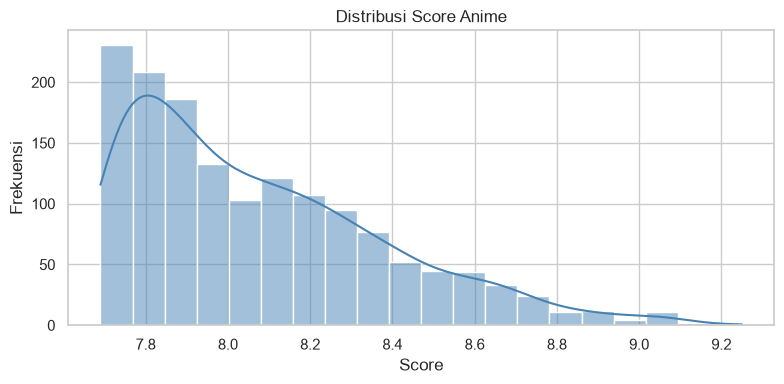

In [21]:
plt.figure(figsize=(8, 4))
sns.histplot(data=df, x="Score", bins=20, kde=True, color="steelblue")
plt.title("Distribusi Score Anime")
plt.xlabel("Score")
plt.ylabel("Frekuensi")
plt.tight_layout()
plt.show()

**Insight:** Distribusi `Score` cenderung miring ke kanan. Sebagian besar anime memiliki skor sekitar 7,7–8,2, sedangkan skor tinggi di atas 8,8 lebih jarang.

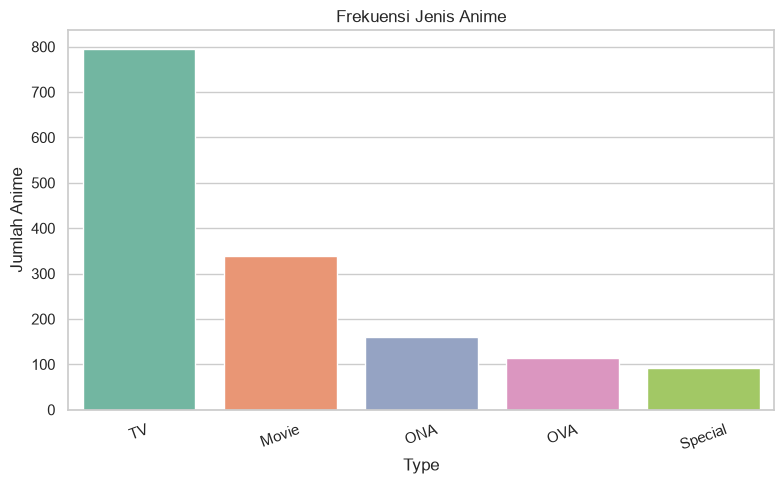

In [22]:
plt.figure(figsize=(8, 5))
type_counts = df["Type"].value_counts()
sns.barplot(x=type_counts.index, y=type_counts.values, hue=type_counts.index, palette="Set2", legend=False)
plt.title("Frekuensi Jenis Anime")
plt.xlabel("Type")
plt.ylabel("Jumlah Anime")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:** `TV` merupakan jenis anime yang paling sering muncul, sedangkan `Special` paling sedikit. Komposisi data didominasi oleh format serial dan film.

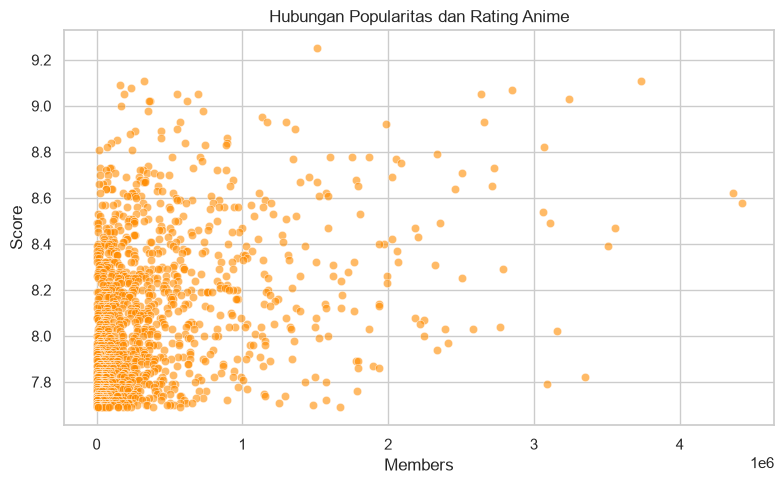

Korelasi Members-Score: 0.347


In [24]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Members", y="Score", alpha=0.6, color="darkorange")
plt.title("Hubungan Popularitas dan Rating Anime")
plt.xlabel("Members")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

score_members_corr = df[["Members", "Score"]].corr().loc["Members", "Score"]
print(f"Korelasi Members-Score: {score_members_corr:.3f}")

**Insight:** Terdapat hubungan positif yang lemah-sedang antara `Members` dan `Score`. Anime dengan lebih banyak anggota cenderung memiliki skor lebih tinggi, tetapi variasi rating tetap besar pada setiap tingkat popularitas.

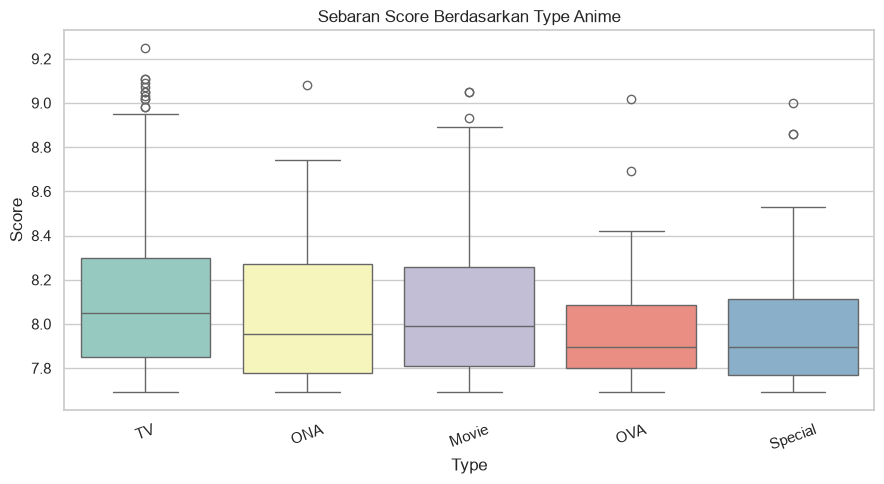

In [25]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Type", y="Score", hue="Type", palette="Set3", legend=False)
plt.title("Sebaran Score Berdasarkan Type Anime")
plt.xlabel("Type")
plt.ylabel("Score")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

**Insight:** `TV` memiliki median `Score` paling tinggi dan sebaran rating yang relatif lebar. Beberapa kategori juga memiliki outlier skor tinggi, sehingga terdapat anime dengan performa rating yang jauh di atas mayoritas kategorinya.

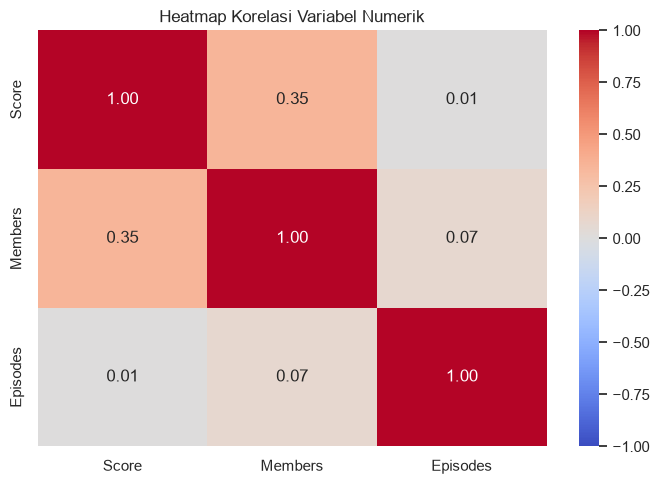

In [26]:
correlation_columns = ["Score", "Members", "Episodes"]
correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(7, 5))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1)
plt.title("Heatmap Korelasi Variabel Numerik")
plt.tight_layout()
plt.show()

**Insight:** Korelasi paling terlihat adalah antara `Members` dan `Score` dengan nilai sekitar 0,35, yang menunjukkan hubungan positif sedang. `Episodes` hampir tidak berkorelasi dengan `Score` maupun `Members`, sehingga jumlah episode bukan indikator kuat untuk rating atau popularitas.